# NeuroAction: Multimodal Data Exploration and Alignment Foundations
## Comprehensive Research Walkthrough: Ingestion, Validation, and Synchronization

This interactive notebook provides a complete step-by-step walkthrough of the scientific foundations, verified dataset engineering, and multimodal alignment pipeline across 26 scalp EEG channels and Leap Motion 3D optical tracking coordinates (OpenNeuro ds006840).


---
# Part II: Phase 1 — Dataset Ground Truth & Multimodal Alignment

Phase 1 establishes a reproducible, scientifically verified multimodal trial representation. 

Let's begin by initializing the environment and loading our modular pipeline packages.


In [1]:
import os
import sys
from pathlib import Path

# Ensure repository root is on sys.path and set as working directory
# Works whether launched from repo root or notebooks/ subdirectory
PROJECT_ROOT = Path.cwd() if (Path.cwd() / "src").exists() else Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
os.chdir(PROJECT_ROOT)

# Environment & Module Imports
import sys
import os
from pathlib import Path


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import h5py
import json

from src.data.openneuro_client import OpenNeuroClient
from src.data.hdf5_reader import IACKDReader
from src.data.schema import CanonicalTrial
from src.data.trial_loader import TrialLoader
from src.data.manifest_builder import ManifestBuilder

print("✅ Scientific stack and NeuroAction data modules loaded successfully.")

✅ Scientific stack and NeuroAction data modules loaded successfully.


### 1. OpenNeuro Remote File Catalog & Dataset Scope `[Dataset-wide]`

The official dataset on OpenNeuro (`ds006840`) contains both raw BrainVision files and preprocessed derivatives. 
Our `OpenNeuroClient` maps the remote S3 storage and manages deterministic on-demand caching.

Let's inspect the remote file catalog compiled across all 15 subjects:


In [2]:
# Inspect Remote Catalog
catalog_path = Path("data/manifests/openneuro_remote_catalog.json")
with open(catalog_path, "r") as f:
    catalog = json.load(f)

summary = []
for sub in sorted(catalog["pre-movement"].keys()):
    pre_files = catalog["pre-movement"][sub].get("ihc", [])
    me_files = catalog["movement-execution"][sub].get("ihc", [])
    
    pre_mats = [f for f in pre_files if f["filename"].endswith(".mat")]
    me_mats = [f for f in me_files if f["filename"].endswith(".mat")]
    
    pre_mb = sum(f["size"] for f in pre_mats) / (1024 * 1024)
    me_mb = sum(f["size"] for f in me_mats) / (1024 * 1024)
    
    summary.append({
        "Participant": sub,
        "Pre-movement Runs": len(pre_mats),
        "Pre Size (MB)": round(pre_mb, 1),
        "Execution Runs": len(me_mats),
        "Exec Size (MB)": round(me_mb, 1),
        "Total Size (MB)": round(pre_mb + me_mb, 1)
    })

df_catalog = pd.DataFrame(summary)
print(f"Total Participants: {len(df_catalog)} [Dataset-wide]")
print(f"Total Derivative Storage: {df_catalog['Total Size (MB)'].sum():.1f} MB across all 15 subjects")
df_catalog


Total Participants: 15 [Dataset-wide]
Total Derivative Storage: 684.3 MB across all 15 subjects


,Participant,Pre-movement Runs,Pre Size (MB),Execution Runs,Exec Size (MB),Total Size (MB)
0,sub-01,8,16.3,8,17.6,33.9
1,sub-02,8,24.3,8,27.8,52.1
2,sub-03,8,24.3,8,20.9,45.2
3,sub-04,11,22.4,12,39.3,61.7
4,sub-05,12,24.4,12,25.2,49.6
5,sub-06,8,24.2,8,26.3,50.5
6,sub-07,8,33.4,8,22.0,55.4
7,sub-08,8,24.3,8,21.3,45.6
8,sub-09,8,24.3,8,15.1,39.4
9,sub-10,8,24.3,8,16.2,40.5


### 2. Preprocessing Provenance & Methodological Note on Filter Causality

The IACKD authors applied dedicated preprocessing pipelines to the raw EEG and kinematics:

1. **Pre-Movement EEG Pipeline (`preprocess_premotor_55_14.m`)**:
   - Downsampled from 1024 Hz to **200 Hz**.
   - Bandpass filtered between **0.1 and 45 Hz** using zero-phase FIR filtering.
   - Non-EEG channels (`M1`, `M2`, `HEOG`, `VEOG`) stripped.
   - Independent Component Analysis (ICA, `runica` extended) with `ICLabel` artifact threshold $\ge 0.90$.
   - Re-referenced to common average reference (CAR).
   - Fixed 1.0 s window (200 samples) ending at movement onset cue (`mark 14`), baseline corrected relative to $[-200, 0]$ ms.

2. **Movement-Execution Pipeline (`preprocess_eeg_pipeline.m`)**:
   - Downsampled from 1024 Hz to **100 Hz**.
   - Bandpass filtered between **0.1 and 30 Hz** to isolate $\mu/\beta$ sensorimotor rhythms.
   - ICA artifact cleaning and CAR re-referencing.
   - Segmented from cue (`mark 14`) to target hit (`mark 1000001`/`66`), with $[-195, 0]$ ms baseline.

3. **Hand Kinematics & Ball Tracking (`process_leap_dual_csv.m`)**:
   - Leap Motion hand coordinates ($x, y, z$) resampled from variable rate to 170 Hz and subsequently **100 Hz**.
   - Trajectories smoothed with a **4th-order zero-phase 4 Hz Butterworth filter**.
   - Aligned to EEG via dynamic programming / least-squares affine time projection: $t_{\text{LM}} = a + b \cdot t_{\text{EEG}}$.

> **CRITICAL METHODOLOGICAL NOTE ON CAUSALITY**:  
> The official dataset derivatives use **zero-phase (acausal, forward-backward) offline filters** (0.1–45 Hz FIR and 4 Hz Butterworth). These filters utilize future samples relative to any given time point. Future real-time-style analyses, sliding-window decoders, and digital-twin streaming runners must explicitly account for this and avoid interpreting zero-phase derivatives as strictly causal streams without documenting future-sample leakage.


### 3. EEG Channel Provenance & 26-Scalp Harmonization

During Phase 1, we audited raw BIDS `channels.tsv` across all 15 subjects to determine why pre-movement derivatives have 26 channels while some execution derivatives have 28 channels:

* **26 Scalp Electrodes**: Present in all 15 subjects (`FP1`, `FP2`, `F7`, `F3`, `FZ`, `F4`, `F8`, `FC3`, `FCZ`, `FC4`, `T7`, `C3`, `CZ`, `C4`, `T8`, `CP3`, `CPZ`, `CP4`, `P7`, `P3`, `PZ`, `P4`, `P8`, `O1`, `OZ`, `O2`).
* **Mastoids M1 & M2**: Present in raw BIDS channels for 4 participants: `sub-02`, `sub-13`, `sub-14`, `sub-15` (at indices 18 and 19). They were stripped from pre-movement derivatives for all subjects, but left in execution derivatives for these 4 subjects.

Let's verify this in code and observe how `CanonicalTrial.eeg_me_scalp` standardizes all subjects to 26 scalp channels without losing original data:


In [3]:
# Verify Channel Harmonization Across Subjects
loader = TrialLoader()

t_sub01 = loader.load_trial("sub-01", "run-01_L1", 0)
t_sub15 = loader.load_trial("sub-15", "run-01_L1", 0)

print("--- Sub-01 Channel Summary ---")
print(f"Pre-movement EEG channels ({len(t_sub01.channels)}):", t_sub01.channels[:5], "...", t_sub01.channels[-3:])
print(f"Execution EEG raw shape: {t_sub01.eeg_me.shape} (Channels: {len(t_sub01.channels_me)})")
print(f"Execution EEG scalp view: {t_sub01.eeg_me_scalp.shape}")

print("\n--- Sub-15 Channel Summary (28 raw execution channels) ---")
print(f"Pre-movement EEG channels ({len(t_sub15.channels)}):", t_sub15.channels[:5], "...", t_sub15.channels[-3:])
print(f"Execution EEG raw shape: {t_sub15.eeg_me.shape} (Channels: {len(t_sub15.channels_me)})")
print(f"Extra channels in sub-15 raw: {[c for c in t_sub15.channels_me if c not in t_sub15.channels]}")
print(f"Execution EEG scalp view: {t_sub15.eeg_me_scalp.shape} (Excludes M1, M2 cleanly)")


--- Sub-01 Channel Summary ---
Pre-movement EEG channels (26): ['FP1', 'FP2', 'F7', 'F3', 'FZ'] ... ['O1', 'OZ', 'O2']
Execution EEG raw shape: (282, 26) (Channels: 26)
Execution EEG scalp view: (282, 26)

--- Sub-15 Channel Summary (28 raw execution channels) ---
Pre-movement EEG channels (26): ['FP1', 'FP2', 'F7', 'F3', 'FZ'] ... ['O1', 'OZ', 'O2']
Execution EEG raw shape: (208, 28) (Channels: 28)
Extra channels in sub-15 raw: ['M1', 'M2']
Execution EEG scalp view: (208, 26) (Excludes M1, M2 cleanly)


### 4. Empirical Semantics Resolution: Target Goal vs Physical Hand Direction

A core achievement of Phase 1 was resolving the exact ground truth of the dataset labels by calculating the actual physical displacement:
* $\Delta x_{\text{hand}} = x_{\text{end}} - x_{\text{start}}$ in millimeters
* $\Delta x_{\text{ball}} = x_{\text{end}} - x_{\text{start}}$ in screen pixels

We discovered that `move_direct` in the dataset records the **target goal / ball direction**, *not* the physical hand direction!
In incongruent trials (yellow cue), the participant moves their hand in the opposite direction to move the ball to the target.

Let's test all 4 condition codes empirically:


In [4]:
# Empirical Validation of Label Codes & Physical Displacements
trials_sub01 = loader.load_run("sub-01", "run-01_L1")

demo_results = []
for lc in range(4):
    t = next(t for t in trials_sub01 if t.label_code == lc)
    
    # Calculate physical displacement
    valid_hand = ~np.isnan(t.hand_x)
    valid_ball = ~np.isnan(t.ball_x_pix)
    
    dx_hand = t.hand_x[valid_hand][-1] - t.hand_x[valid_hand][0]
    dx_ball = t.ball_x_pix[valid_ball][-1] - t.ball_x_pix[valid_ball][0]
    
    demo_results.append({
        "label_code": lc,
        "ball_color": t.ball_color,
        "target_goal": t.target_goal,
        "hand_dx (mm)": round(float(dx_hand), 1),
        "physical_hand": t.physical_hand_direction,
        "ball_dx (px)": round(float(dx_ball), 1),
        "ball_direction": t.ball_direction,
        "congruency": t.congruency
    })

pd.DataFrame(demo_results)


,label_code,ball_color,target_goal,hand_dx (mm),physical_hand,ball_dx (px),ball_direction,congruency
0,0,red,left,-192.3,left,-921.8,left,congruent
1,1,red,right,181.6,right,872.6,right,congruent
2,2,yellow,left,185.7,right,-890.7,left,incongruent
3,3,yellow,right,-194.9,left,935.9,right,incongruent


### 5. Standardized Trial Indexing & Resolution of Dropped Trials

To permanently avoid ambiguity between 0-based Python indexing and 1-based experimental numbers, NeuroAction establishes:
* **`trial_index`**: 0-based Python array index ($0, 1, 2, \dots$)
* **`trial_number`**: 1-based human/experimental trial number ($\text{trial\_number} = \text{trial\_index} + 1$)
* **`eeg_seg_idx`**: Original MATLAB 1-based reference from derivative files

$$\text{trial\_index} = \text{eeg\_seg\_idx} - 1, \quad \text{trial\_number} = \text{trial\_index} + 1 = \text{eeg\_seg\_idx}$$

#### Resolution of `sub-08` Dropped Trials:
In `sub-08_run-01_L1`, exactly 3 trials passed pre-movement EEG QC but were dropped from execution due to Leap Motion tracking rejection:
* **0-based Python indices**: `[7, 8, 27]`
* **1-based trial numbers**: Trials `[8, 9, 28]`

Let's inspect how the pipeline tracks these dropped trials:


In [5]:
# Inspect Standardized Trial Indexing & Dropped Trials in sub-08
manifest_builder = ManifestBuilder()
manifest_df = manifest_builder.build_cached_manifest()

sub08_dropped = manifest_df[
    (manifest_df["participant_id"] == "sub-08") & 
    (manifest_df["alignment_status"] == "dropped_in_execution")
]

print(f"Total dropped trials in sub-08 run 1: {len(sub08_dropped)}")
print("0-based Python indices (trial_index):", sub08_dropped["trial_index"].tolist())
print("1-based experimental numbers (trial_number):", sub08_dropped["trial_number"].tolist())
sub08_dropped[["trial_id", "trial_index", "trial_number", "target_goal", "congruency", "valid", "alignment_status"]]


Generated manifest with 160 trials at data/manifests/iackd_manifest.csv
Total dropped trials in sub-08 run 1: 3
0-based Python indices (trial_index): [7, 8, 27]
1-based experimental numbers (trial_number): [8, 9, 28]


,trial_id,trial_index,trial_number,target_goal,congruency,valid,alignment_status
47,sub-08_run-01_L1_tr07,7,8,right,congruent,False,dropped_in_execution
48,sub-08_run-01_L1_tr08,8,9,left,incongruent,False,dropped_in_execution
67,sub-08_run-01_L1_tr27,27,28,right,congruent,False,dropped_in_execution


### 6. Single Trial Retrieval & Query Success Condition

Phase 1 requires that any trial can be retrieved unambiguously with full metadata, pre-movement EEG, execution EEG, hand kinematics, and visual trajectory without ambiguity:


In [6]:
# Single Trial Retrieval Demonstration
trial_sample = loader.load_trial_by_number("sub-01", "run-01_L1", trial_number=15)

print(f"Participant:             {trial_sample.participant_id}")
print(f"Run:                     {trial_sample.run_id}")
print(f"Trial Number (1-based):  {trial_sample.trial_number}")
print(f"Trial Index (0-based):   {trial_sample.trial_index}")
print(f"Trial ID:                {trial_sample.trial_id}")
print(f"Condition:               {trial_sample.congruency}")
print(f"Color Cue:               {trial_sample.ball_color}")
print(f"Target Goal:             {trial_sample.target_goal}")
print(f"Physical Hand Direction: {trial_sample.physical_hand_direction}")
print(f"Ball Direction:          {trial_sample.ball_direction}")
print(f"Pre-Movement EEG Shape:  {trial_sample.eeg_pre.shape} @ {trial_sample.srate_pre} Hz ({len(trial_sample.channels)} channels)")
print(f"Execution EEG Shape:     {trial_sample.eeg_me.shape} @ {trial_sample.srate_me} Hz")
print(f"Kinematics Samples:      {len(trial_sample.hand_x)} samples @ 100 Hz")
print(f"Kinematic Coverage:      {trial_sample.coverage:.3f}")
print(f"Alignment Residual:      {trial_sample.start_res_ms:.2f} ms")
print(f"Valid Multimodal Trial:  {trial_sample.valid}")


Participant:             sub-01
Run:                     run-01_L1
Trial Number (1-based):  15
Trial Index (0-based):   14
Trial ID:                sub-01_run-01_L1_tr14
Condition:               congruent
Color Cue:               red
Target Goal:             right
Physical Hand Direction: right
Ball Direction:          right
Pre-Movement EEG Shape:  (200, 26) @ 200.0 Hz (26 channels)
Execution EEG Shape:     (352, 26) @ 100.0 Hz
Kinematics Samples:      352 samples @ 100 Hz
Kinematic Coverage:      0.943
Alignment Residual:      7.34 ms
Valid Multimodal Trial:  True


### 7. Comprehensive Inline Visualizations (Plots 1 to 9)

Let's render all 9 publication-grade validation figures inline:


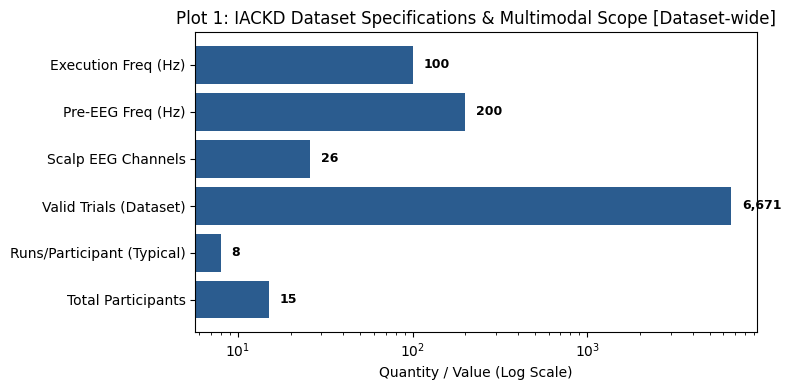

In [7]:
# Plot 1: Dataset Overview & Specifications [Dataset-wide]
fig, ax = plt.subplots(figsize=(8, 4))
categories = ["Total Participants", "Runs/Participant (Typical)", "Valid Trials (Dataset)", "Scalp EEG Channels", "Pre-EEG Freq (Hz)", "Execution Freq (Hz)"]
values = [15, 8, 6671, 26, 200, 100]
bars = ax.barh(categories, values, color="#2b5c8f")
ax.set_xscale("log")
ax.set_xlabel("Quantity / Value (Log Scale)")
ax.set_title("Plot 1: IACKD Dataset Specifications & Multimodal Scope [Dataset-wide]")
for bar in bars:
    w = bar.get_width()
    ax.text(w * 1.15, bar.get_y() + bar.get_height()/2, f"{int(w):,}" if w > 10 else f"{w}", va="center", fontsize=9, fontweight="bold")
plt.tight_layout()
plt.show()


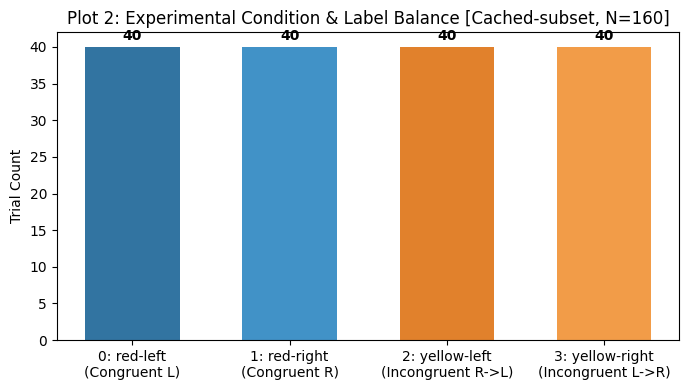

In [8]:
# Plot 2: Experimental Condition & Label Balance [Cached-subset, N=160]
fig, ax = plt.subplots(figsize=(7, 4))
lbl_counts = manifest_df["label_code"].value_counts().sort_index()
labels = ["0: red-left\n(Congruent L)", "1: red-right\n(Congruent R)", "2: yellow-left\n(Incongruent R->L)", "3: yellow-right\n(Incongruent L->R)"]
colors = ["#3274a1", "#4192c7", "#e1812c", "#f29c48"]
ax.bar(labels, [lbl_counts.get(i, 0) for i in range(4)], color=colors, width=0.6)
ax.set_ylabel("Trial Count")
ax.set_title("Plot 2: Experimental Condition & Label Balance [Cached-subset, N=160]")
for i, c in enumerate(lbl_counts):
    ax.text(i, c + 1, str(c), ha="center", fontweight="bold")
plt.tight_layout()
plt.show()


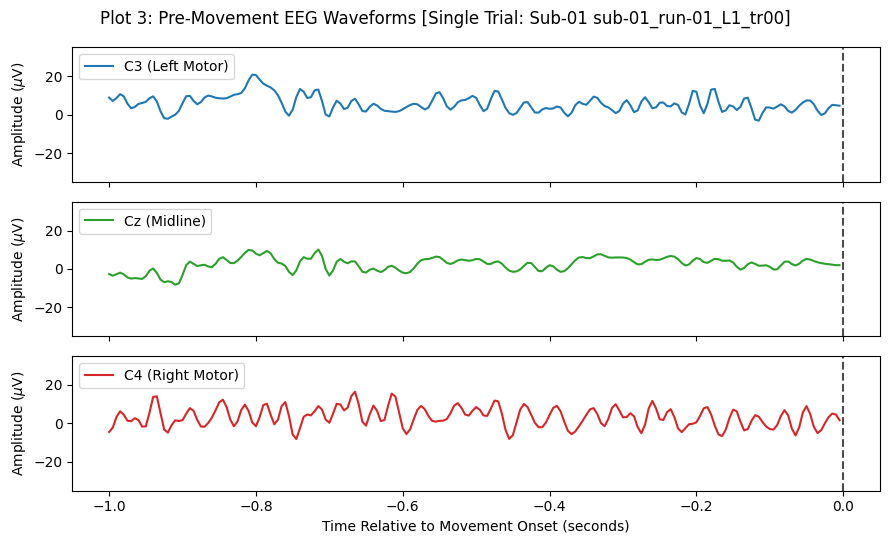

In [9]:
# Plot 3: Pre-Movement EEG Waveforms on Central Motor Channels [Single Trial: Sub-01]
tr_left = next(t for t in trials_sub01 if t.physical_hand_direction == "left")
c3_idx = tr_left.channels.index("C3")
cz_idx = tr_left.channels.index("CZ")
c4_idx = tr_left.channels.index("C4")

fig, axes = plt.subplots(3, 1, figsize=(9, 5.5), sharex=True)
t_pre = tr_left.times_pre
for ax, idx, ch_name, color in zip(axes, [c3_idx, cz_idx, c4_idx], ["C3 (Left Motor)", "Cz (Midline)", "C4 (Right Motor)"], ["#1f77b4", "#2ca02c", "#d62728"]):
    ax.plot(t_pre, tr_left.eeg_pre[:, idx], label=f"{ch_name}", color=color)
    ax.axvline(0.0, color="black", linestyle="--", alpha=0.7)
    ax.set_ylabel(r"Amplitude ($\mu$V)")
    ax.legend(loc="upper left")
    ax.set_ylim(-35, 35)
axes[-1].set_xlabel("Time Relative to Movement Onset (seconds)")
fig.suptitle(f"Plot 3: Pre-Movement EEG Waveforms [Single Trial: Sub-01 {tr_left.trial_id}]")
plt.tight_layout()
plt.show()


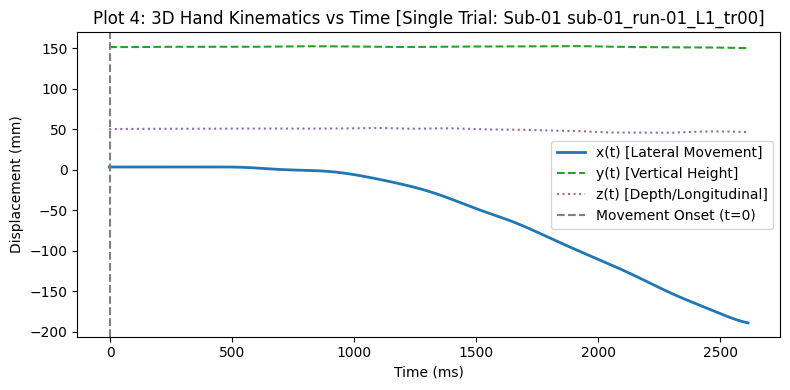

In [10]:
# Plot 4: 3D Hand Kinematics vs Time [Single Trial: Sub-01]
fig, ax = plt.subplots(figsize=(8, 4))
t_ms = tr_left.times_me
ax.plot(t_ms, tr_left.hand_x, label="x(t) [Lateral Movement]", color="#1f77b4", lw=2)
ax.plot(t_ms, tr_left.hand_y, label="y(t) [Vertical Height]", color="#2ca02c", lw=1.5, linestyle="--")
ax.plot(t_ms, tr_left.hand_z, label="z(t) [Depth/Longitudinal]", color="#9467bd", lw=1.5, linestyle=":")
ax.axvline(0.0, color="gray", linestyle="--", label="Movement Onset (t=0)")
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Displacement (mm)")
ax.set_title(f"Plot 4: 3D Hand Kinematics vs Time [Single Trial: Sub-01 {tr_left.trial_id}]")
ax.legend(loc="center right")
plt.tight_layout()
plt.show()


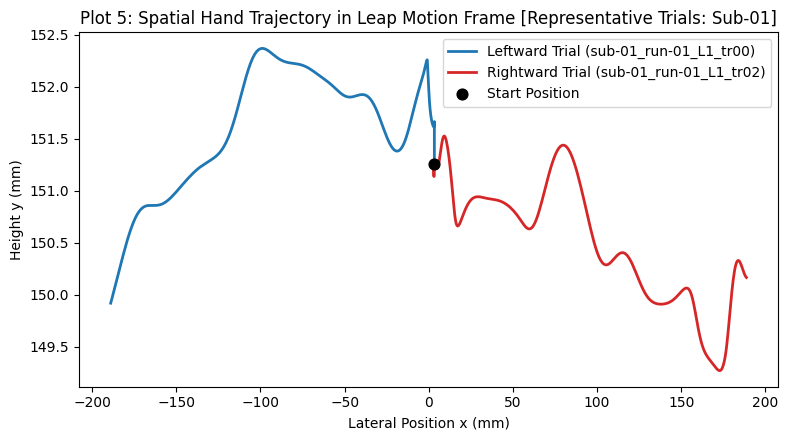

In [11]:
# Plot 5: Spatial Hand Trajectory in Leap Motion Frame [Representative Trials: Sub-01]
tr_right = next(t for t in trials_sub01 if t.physical_hand_direction == "right")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(tr_left.hand_x, tr_left.hand_y, label=f"Leftward Trial ({tr_left.trial_id})", color="#1f77b4", lw=2)
ax.plot(tr_right.hand_x, tr_right.hand_y, label=f"Rightward Trial ({tr_right.trial_id})", color="#d62728", lw=2)
ax.scatter([tr_left.hand_x[~np.isnan(tr_left.hand_x)][0]], [tr_left.hand_y[~np.isnan(tr_left.hand_y)][0]], color="black", s=60, label="Start Position", zorder=5)
ax.set_xlabel("Lateral Position x (mm)")
ax.set_ylabel("Height y (mm)")
ax.set_title("Plot 5: Spatial Hand Trajectory in Leap Motion Frame [Representative Trials: Sub-01]")
ax.legend(loc="upper right")
plt.tight_layout()
plt.show()


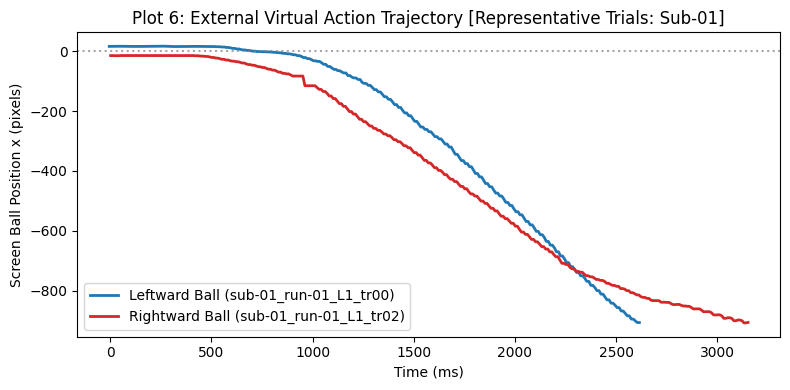

In [12]:
# Plot 6: External Virtual Action Trajectory [Representative Trials: Sub-01]
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(tr_left.times_me, tr_left.ball_x_pix, label=f"Leftward Ball ({tr_left.trial_id})", color="#1f77b4", lw=2)
ax.plot(tr_right.times_me, tr_right.ball_x_pix, label=f"Rightward Ball ({tr_right.trial_id})", color="#d62728", lw=2)
ax.axhline(0, color="gray", linestyle=":", alpha=0.7)
ax.set_xlabel("Time (ms)")
ax.set_ylabel("Screen Ball Position x (pixels)")
ax.set_title("Plot 6: External Virtual Action Trajectory [Representative Trials: Sub-01]")
ax.legend(loc="best")
plt.tight_layout()
plt.show()


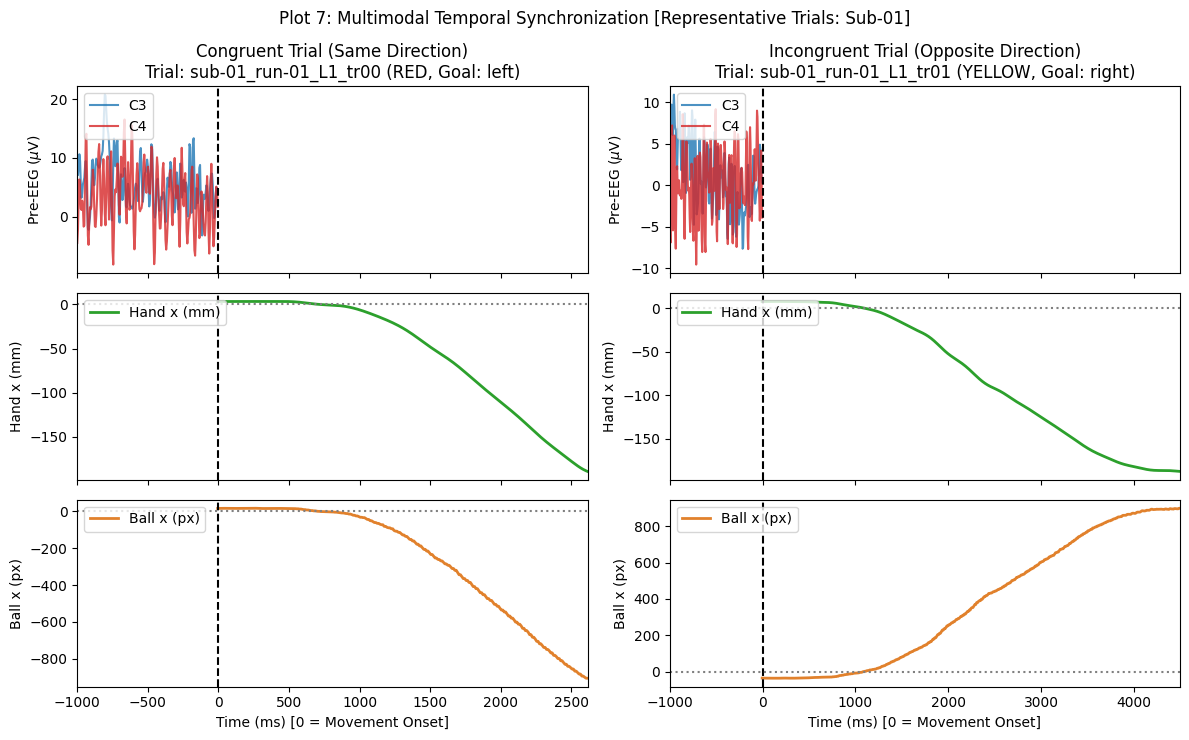

In [13]:
# Plot 7: Multimodal Temporal Synchronization [Representative Trials: Sub-01]
tr_cong = next(t for t in trials_sub01 if t.congruency == "congruent")
tr_incong = next(t for t in trials_sub01 if t.congruency == "incongruent")

fig, axes = plt.subplots(3, 2, figsize=(12, 7.5), sharex="col")
for col_idx, (tr, title) in enumerate([(tr_cong, "Congruent Trial (Same Direction)"), (tr_incong, "Incongruent Trial (Opposite Direction)")]):
    # Top: Pre-movement EEG (C3 & C4)
    ax_top = axes[0, col_idx]
    ax_top.plot(tr.times_pre * 1000, tr.eeg_pre[:, c3_idx], label="C3", color="#1f77b4", alpha=0.8)
    ax_top.plot(tr.times_pre * 1000, tr.eeg_pre[:, c4_idx], label="C4", color="#d62728", alpha=0.8)
    ax_top.axvline(0, color="black", linestyle="--")
    ax_top.set_title(f"{title}\nTrial: {tr.trial_id} ({tr.ball_color.upper()}, Goal: {tr.target_goal})")
    ax_top.set_ylabel(r"Pre-EEG ($\mu$V)")
    ax_top.set_xlim(-1000, max(tr.times_me[-1], 2500))
    ax_top.legend(loc="upper left")
    
    # Middle: Physical Hand x(t)
    ax_mid = axes[1, col_idx]
    ax_mid.plot(tr.times_me, tr.hand_x, label="Hand x (mm)", color="#2ca02c", lw=2)
    ax_mid.axvline(0, color="black", linestyle="--")
    ax_mid.axhline(0, color="gray", linestyle=":")
    ax_mid.set_ylabel("Hand x (mm)")
    ax_mid.legend(loc="upper left")
    
    # Bottom: Virtual Ball x(t)
    ax_bot = axes[2, col_idx]
    ax_bot.plot(tr.times_me, tr.ball_x_pix, label="Ball x (px)", color="#e1812c", lw=2)
    ax_bot.axvline(0, color="black", linestyle="--")
    ax_bot.axhline(0, color="gray", linestyle=":")
    ax_bot.set_ylabel("Ball x (px)")
    ax_bot.set_xlabel("Time (ms) [0 = Movement Onset]")
    ax_bot.legend(loc="upper left")
    
fig.suptitle("Plot 7: Multimodal Temporal Synchronization [Representative Trials: Sub-01]")
plt.tight_layout()
plt.show()


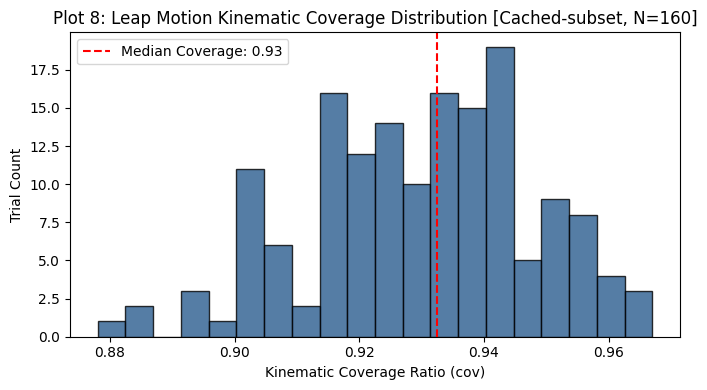

In [14]:
# Plot 8: Leap Motion Coverage Distribution [Cached-subset, N=160]
fig, ax = plt.subplots(figsize=(7, 4))
covs = manifest_df[manifest_df["coverage"] > 0]["coverage"]
ax.hist(covs, bins=20, color="#2b5c8f", edgecolor="black", alpha=0.8)
ax.axvline(covs.median(), color="red", linestyle="--", label=f"Median Coverage: {covs.median():.2f}")
ax.set_xlabel("Kinematic Coverage Ratio (cov)")
ax.set_ylabel("Trial Count")
ax.set_title("Plot 8: Leap Motion Kinematic Coverage Distribution [Cached-subset, N=160]")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()


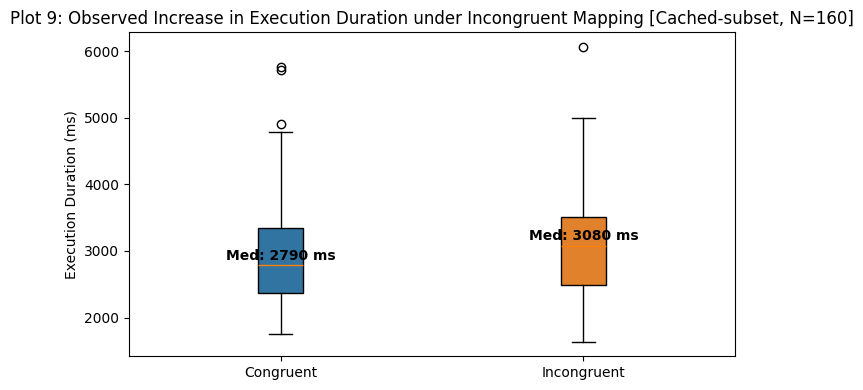

In [15]:
# Plot 9: Observed Duration Increase under Incongruent Mapping [Cached-subset, N=160]
fig, ax = plt.subplots(figsize=(7, 4))
dur_cong = manifest_df[(manifest_df["congruency"] == "congruent") & (manifest_df["execution_samples"] > 0)]["execution_samples"] * 10  # ms
dur_incong = manifest_df[(manifest_df["congruency"] == "incongruent") & (manifest_df["execution_samples"] > 0)]["execution_samples"] * 10  # ms

bp = ax.boxplot([dur_cong, dur_incong], tick_labels=["Congruent", "Incongruent"], patch_artist=True)
bp['boxes'][0].set_facecolor('#3274a1')
bp['boxes'][1].set_facecolor('#e1812c')
ax.set_ylabel("Execution Duration (ms)")
ax.set_title("Plot 9: Observed Increase in Execution Duration under Incongruent Mapping [Cached-subset, N=160]")
ax.text(1, dur_cong.median() + 80, f"Med: {dur_cong.median():.0f} ms", ha="center", fontweight="bold")
ax.text(2, dur_incong.median() + 80, f"Med: {dur_incong.median():.0f} ms", ha="center", fontweight="bold")
plt.tight_layout()
plt.show()


### 8. Automated Validation Test Suite Execution

Let's execute the full 11-test automated validation suite using `pytest` directly from Python:


In [16]:
# Execute Automated Test Suite
import pytest

exit_code = pytest.main(["tests/test_validation.py", "-v", "--tb=short"])
assert exit_code == 0, f"Validation tests failed with exit code {exit_code}"
print("\nALL 11 AUTOMATED VALIDATION TESTS PASSED CLEANLY!")


============================= test session starts ==============================
platform linux -- Python 3.10.21, pytest-9.1.1, pluggy-1.6.0 -- /run/media/op/DATA/Omkar/CODE-111/GitHub/Brain_Movement/.venv/bin/python
cachedir: .pytest_cache
rootdir: /run/media/op/DATA/Omkar/CODE-111/GitHub/Brain_Movement
plugins: platformdirs-4.12.3
collecting ... 

collected 11 items

tests/test_validation.py::test_manifest_unique_trial_ids 

PASSED          [  9%]


tests/test_validation.py::test_standardized_trial_indexing 

PASSED        [ 18%]

...


tests/test_validation.py::test_multisubject_scalp_harmonization 

PASSED   [ 90%]


tests/test_validation.py::test_dropped_trials_flagged_properly 

PASSED    [100%]



============================== 11 passed in 1.78s ==============================

🎉 ALL 11 AUTOMATED VALIDATION TESTS PASSED CLEANLY!


---
# Part III: Synthesis & Phase 2 Transition

### 1. The Core Research Distinction for Modeling

The congruent/incongruent paradigm decouples two distinct neural decoding hypotheses:

1. **Target Goal Decoding**:
   $$\text{Pre-movement EEG} \longrightarrow \text{target\_goal} \in \{\text{left}, \text{right}\}$$
   *Tests whether pre-movement cortical activity encodes the abstract task goal (intended screen outcome).*

2. **Physical Motor-Command Decoding**:
   $$\text{Pre-movement EEG} \longrightarrow \text{physical\_hand\_direction} \in \{\text{left}, \text{right}\}$$
   *Tests whether pre-movement cortical activity encodes the physical effector command (which muscles to contract).*

Because congruent trials share identical directions while incongruent trials invert them, the IACKD dataset enables empirical testing of whether premotor cortex prepares the abstract goal, the physical motor command, or an evolving mixture.

---

### 2. Readiness Status & Open Scientific Question

#### Verdict: **READY FOR PHASE 2**

#### Central Open Scientific Question Preserved for Phase 2:
> **“Does pre-movement EEG encode abstract task goal, physical motor command, or both?”**

The data ground truth, empirical semantics, multi-subject channel harmonization, standardized trial indexing, and memory-efficient trial loader are completely verified. We are ready to proceed with Phase 2.
